# Tutorial: Lineare Regression mit Python (20 Min.)

**Ziel:** Du passt eine lineare Regression an echte Daten an, liest die Ausgabe und prüfst, ob man dem Modell trauen kann. Am Ende findest du drei Fehler in einem kaputten Notebook.
Daten: Boston Housing (506 Zählbezirke), der Datensatz aus Lab 3.6 in *An Introduction to Statistical Learning*. Er liegt bei, ein Download ist nicht nötig.

Von oben nach unten arbeiten. Zellen mit `...` sind Lücken zum Ausfüllen. Die erwarteten Werte stehen in der Tutorial-README, die Antworten in `LOESUNGEN.md`.

## Step 0 / Schritt 0

In [1]:
import numpy as np, pandas as pd, matplotlib, matplotlib.pyplot as plt, statsmodels, sklearn
import statsmodels.api as sm, statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

print('numpy', np.__version__, '| pandas', pd.__version__, '| statsmodels', statsmodels.__version__, '| scikit-learn', sklearn.__version__)
SEED = 42
np.random.seed(SEED)
Boston = pd.read_csv("Boston.csv")      # 506 tracts, 13 columns (from the ISLP package)
print(Boston.shape)

numpy 2.5.3 | pandas 3.0.5 | statsmodels 0.15.0 | scikit-learn 1.9.1
(506, 13)


## Aufgabe 1: Einfache Regression

In [2]:
simple = smf.ols("medv ~ lstat", data=Boston).fit()
print(simple.summary().tables[1])
print(f"R2 = {simple.rsquared:.3f}, RSE = {np.sqrt(simple.scale):.3f}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     34.5538      0.563     61.415      0.000      33.448      35.659
lstat         -0.9500      0.039    -24.528      0.000      -1.026      -0.874
R2 = 0.544, RSE = 6.216


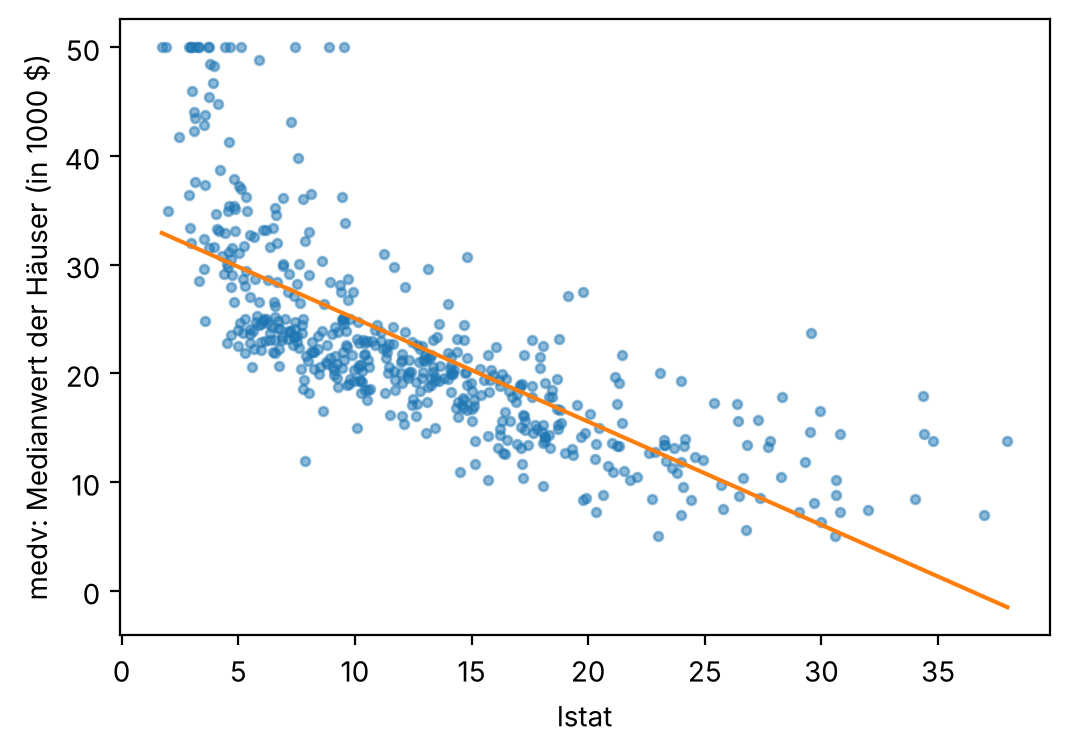

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(Boston.lstat, Boston.medv, s=10, alpha=.5)
xs = np.linspace(Boston.lstat.min(), Boston.lstat.max(), 100)
ax.plot(xs, simple.params["Intercept"] + simple.params["lstat"] * xs, color="C1")
ax.set_xlabel("lstat"); ax.set_ylabel("medv: Medianwert der Häuser (in 1000 $)"); plt.show()

Dieselbe Gerade mit scikit-learn (keine p-Werte, für Vorhersagen gebaut):

In [4]:
X, y = Boston[["lstat"]], Boston["medv"]
lr = LinearRegression().fit(X, y)
print(lr.intercept_.round(3), lr.coef_.round(3), round(lr.score(X, y), 3), round(mean_squared_error(y, lr.predict(X)), 2))

34.554 [-0.95] 0.544 38.48


**Du bist dran.** Passe `medv ~ rm` (mittlere Zimmerzahl) an. Gib Steigung und R² an.

In [5]:
fit_rm = smf.ols("medv ~ rm", data=Boston).fit()
print(fit_rm.params.round(3).to_dict(), round(fit_rm.rsquared, 3))

{'Intercept': -34.671, 'rm': 9.102} 0.484


## Aufgabe 2: Intervalle und ein zweiter Prädiktor

Bei `lstat = 10`: Konfidenzintervall für den *Mittelwert* von medv und das breitere Prognoseintervall für *einen* Bezirk.

In [6]:
new = pd.DataFrame({"lstat": [10]})
print(simple.get_prediction(new).summary_frame(alpha=0.05).round(2).T)

                   0
mean           25.05
mean_se         0.29
mean_ci_lower  24.47
mean_ci_upper  25.63
obs_ci_lower   12.83
obs_ci_upper   37.28


Ein zweiter Prädiktor. Beobachte, wie sich der Koeffizient von `lstat` verschiebt.

In [7]:
two = smf.ols("medv ~ lstat + age", data=Boston).fit()
print(two.params.round(4).to_dict(), round(two.rsquared, 3))

{'Intercept': 33.2228, 'lstat': -1.0321, 'age': 0.0345} 0.551


## Aufgabe 3 (Zusatz): Alle Prädiktoren und VIF

**Du bist dran.** Passe `medv` an alle 12 übrigen Spalten an, gib die p-Werte aus und berechne den VIF jedes Prädiktors.

In [8]:
cols = [c for c in Boston.columns if c != "medv"]
full = smf.ols("medv ~ " + " + ".join(cols), data=Boston).fit()
print(full.pvalues.round(3).to_string())
X = sm.add_constant(Boston[cols])
print({c: round(vif(X.values, i), 1) for i, c in enumerate(X.columns) if c != "const"})

Intercept    0.000
crim         0.000
zn           0.001
indus        0.829
chas         0.001
nox          0.000
rm           0.000
age          0.787
dis          0.000
rad          0.000
tax          0.001
ptratio      0.000
lstat        0.000
{'crim': np.float64(1.8), 'zn': np.float64(2.3), 'indus': np.float64(4.0), 'chas': np.float64(1.1), 'nox': np.float64(4.4), 'rm': np.float64(1.9), 'age': np.float64(3.1), 'dis': np.float64(4.0), 'rad': np.float64(7.4), 'tax': np.float64(9.0), 'ptratio': np.float64(1.8), 'lstat': np.float64(2.9)}


## Aufgabe 4: Residuen und ein quadratischer Term

Residuen gegen angepasste Werte sollten wie Rauschen aussehen. Eine Kurve heißt: Die Gerade hat die falsche Form.

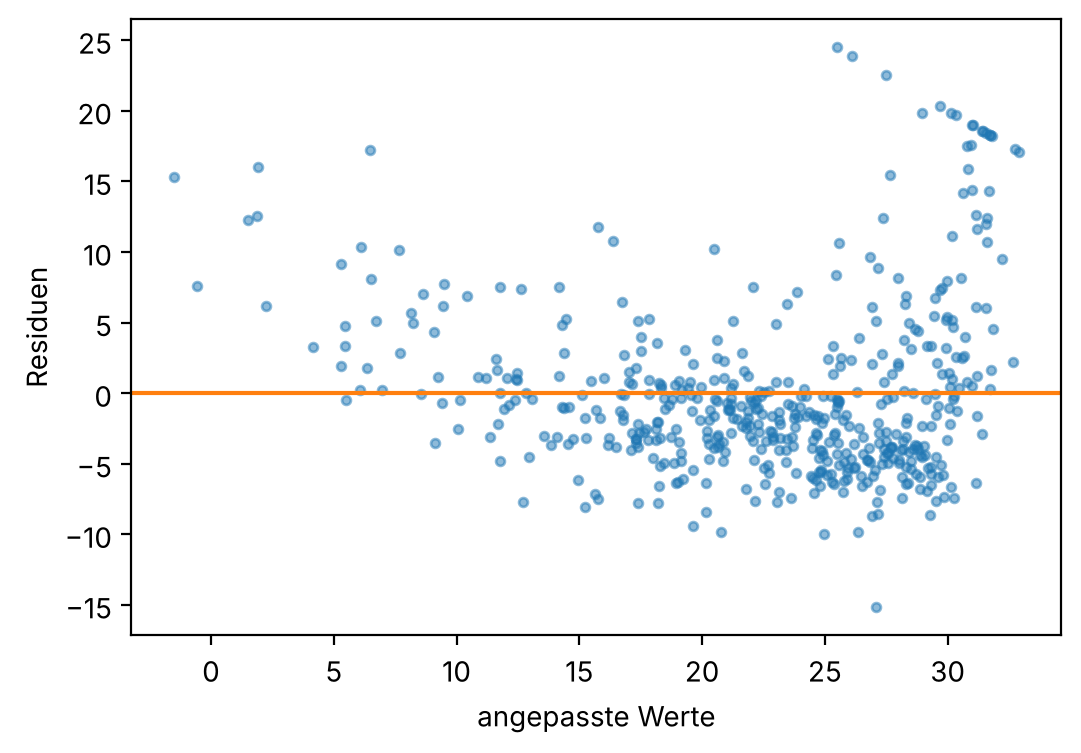

In [9]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(simple.fittedvalues, simple.resid, s=10, alpha=.5)
ax.axhline(0, color="C1")
ax.set_xlabel("angepasste Werte"); ax.set_ylabel("Residuen"); plt.show()

**Du bist dran.** Ergänze `I(lstat**2)`, gib R² an und vergleiche beide Modelle mit `anova_lm`.

In [10]:
quad = smf.ols("medv ~ lstat + I(lstat**2)", data=Boston).fit()
print(round(quad.rsquared, 3))
print(anova_lm(simple, quad))

0.641
   df_resid           ssr  df_diff     ss_diff           F        Pr(>F)
0     504.0  19472.381418      0.0         NaN         NaN           NaN
1     503.0  15347.243158      1.0  4125.13826  135.199822  7.630116e-28


## Aufgabe 5 (Zusatz): Fehlersuche

Öffne `Fehlerhaftes_Notebook.ipynb`.